# Q8: Paired t-Test – Training Evaluation
**Aim:** To test whether the training programme significantly improves scholars' scores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("08_Paired_T_Test_Training.csv")
except FileNotFoundError:
    np.random.seed(42)
    before = np.random.normal(60, 8, 50).round()
    df = pd.DataFrame({"Scholar_ID": [f"R{i:02d}" for i in range(1, 51)], "Score_Before": before,
                       "Score_After": (before + np.random.normal(6, 5, 50)).round()})
df.head()

,Scholar_ID,Score_Before,Score_After
0,R01,64.0,72.0
1,R02,59.0,63.0
2,R03,65.0,68.0
3,R04,72.0,81.0
4,R05,58.0,69.0


### 1. Descriptive statistics

In [3]:
df[["Score_Before", "Score_After"]].agg(["mean", "median", "std", "var"]).round(2)

,Score_Before,Score_After
mean,58.24,64.34
median,58.00,63.50
std,7.50,9.11
var,56.19,82.92


### 2. Difference (After − Before)

In [4]:
df["Difference"] = df["Score_After"] - df["Score_Before"]
d = df["Difference"]
df.head()

,Scholar_ID,Score_Before,Score_After,Difference
0,R01,64.0,72.0,8.0
1,R02,59.0,63.0,4.0
2,R03,65.0,68.0,3.0
3,R04,72.0,81.0,9.0
4,R05,58.0,69.0,11.0


### 3. Hypotheses
- H0: μd ≤ 0 (no improvement)
- H1: μd > 0 (training improves scores), α = 0.05

### 4. Normality of differences

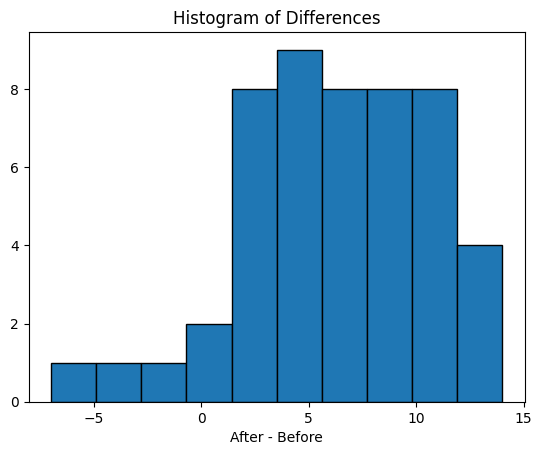

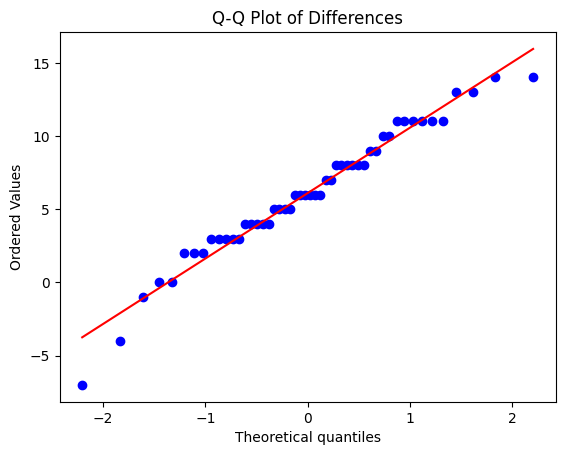

Shapiro-Wilk W = 0.970, p = 0.2410 -> Normal


In [5]:
plt.hist(d, bins=10, edgecolor="black")
plt.title("Histogram of Differences")
plt.xlabel("After - Before")
plt.show()
stats.probplot(d, plot=plt)
plt.title("Q-Q Plot of Differences")
plt.show()
W, p = stats.shapiro(d)
print(f"Shapiro-Wilk W = {W:.3f}, p = {p:.4f} ->", "Normal" if p > 0.05 else "Not normal")

### 5. Paired t-test: t, df, p-value, 95% CI

In [6]:
t, p = stats.ttest_rel(df["Score_After"], df["Score_Before"], alternative="greater")
n = len(d)
ci = stats.t.interval(0.95, n - 1, loc=d.mean(), scale=stats.sem(d))
print(f"t = {t:.3f}, df = {n - 1}, p (one-tailed) = {p:.6f}")
print(f"Mean improvement = {d.mean():.2f}, 95% CI = ({ci[0]:.2f}, {ci[1]:.2f})")
print("Reject H0: training significantly improves scores" if p < 0.05 else "Fail to reject H0")

t = 9.753, df = 49, p (one-tailed) = 0.000000
Mean improvement = 6.10, 95% CI = (4.84, 7.36)
Reject H0: training significantly improves scores


### 6. Cohen's dz

In [7]:
dz = d.mean() / d.std()
size = "negligible" if abs(dz) < 0.2 else "small" if abs(dz) < 0.5 else "medium" if abs(dz) < 0.8 else "large"
print(f"Cohen's dz = {dz:.3f} -> {size} improvement")

Cohen's dz = 1.379 -> large improvement


### 7. Scholars with improvement below the mean improvement

In [8]:
df[d < d.mean()]

,Scholar_ID,Score_Before,Score_After,Difference
1,R02,59.0,63.0,4.0
2,R03,65.0,68.0,3.0
6,R07,73.0,75.0,2.0
7,R08,66.0,70.0,4.0
10,R11,56.0,60.0,4.0
11,R12,56.0,61.0,5.0
12,R13,62.0,62.0,0.0
13,R14,45.0,45.0,0.0
16,R17,52.0,58.0,6.0
19,R20,49.0,52.0,3.0


### 8. Wilcoxon signed-rank test (non-parametric)

In [9]:
W, p = stats.wilcoxon(df["Score_After"], df["Score_Before"], alternative="greater")
print(f"Wilcoxon W = {W:.1f}, p = {p:.6f} ->", "Reject H0" if p < 0.05 else "Fail to reject H0")

Wilcoxon W = 1135.5, p = 0.000000 -> Reject H0


### 9. Paired plot and boxplot

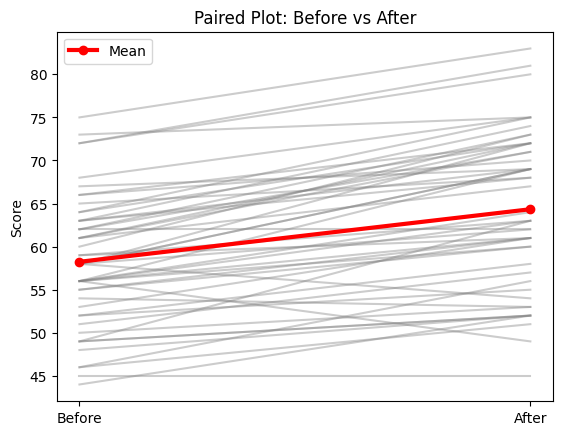

In [10]:
plt.plot([0, 1], df[["Score_Before", "Score_After"]].T.values, color="gray", alpha=0.4)
plt.plot([0, 1], [df["Score_Before"].mean(), df["Score_After"].mean()], "ro-", linewidth=3, label="Mean")
plt.xticks([0, 1], ["Before", "After"])
plt.ylabel("Score")
plt.title("Paired Plot: Before vs After")
plt.legend()
plt.show()

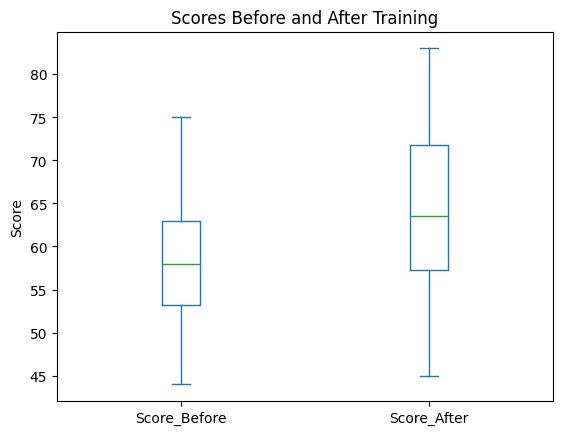

In [11]:
df[["Score_Before", "Score_After"]].plot(kind="box", title="Scores Before and After Training")
plt.ylabel("Score")
plt.show()

**Result:** Paired t-test, effect size and Wilcoxon signed-rank test were performed to evaluate the training programme.